In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df=pd.read_csv('c:/Users/ROHAN/Downloads/D61. Wardwise Covid beds_3_cleaned.csv')
df.head()

,City Name,Area Name,Day-Month-Year,Ward No.,Ward Name,Type of hospital_PrivateorPublic,Longitude,Latitude,Total no. of beds,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD
0,Kalyan Dombivali,DOMBIVLI West,44573,63,Kopar Road,Apurva Hospital Private,73.13,19.236,15.0,NaN,NaN,NaN
1,Kalyan Dombivali,DOMBIVLI West,44573,61,Vishnu Nagar,Life Line Hospital Private,73.13,19.236,23.0,NaN,6.0,NaN
2,Kalyan Dombivali,DOMBIVLI West,44573,61,Vishnu Nagar,Apex Hospital Private,73.13,19.236,26.0,NaN,4.0,1.0
3,Kalyan Dombivali,DOMBIVLI West,44573,61,Vishnu Nagar,Apple Hospital Private,73.13,19.236,27.0,10.0,9.0,3.0
4,Kalyan Dombivali,DOMBIVLI West,44573,59,Kanhoji Jedhe Maidan,Spandan Hospital Private,73.13,19.236,22.0,8.0,4.0,NaN


In [7]:
df.shape

(182, 12)

In [11]:
df.columns
print(df.isnull().sum())

City Name                            1
Area Name                            3
Day-Month-Year                       6
Ward No.                            13
Ward Name                            3
Type of hospital_PrivateorPublic    14
Longitude                           71
Latitude                            71
Total no. of beds                   39
Number of COVID beds                71
Number of ICU beds                  49
Number of ventilators or ABD        71
dtype: int64


In [13]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe(include='object')
df.describe()

C:\Users\ROHAN\AppData\Local\Temp\ipykernel_21848\2047260282.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Total no. of beds,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD
count,143.000000,111.000000,133.000000,111.000000
mean,23.587413,8.108108,4.413534,1.531532
std,20.334640,13.698939,5.365614,3.068372
min,0.000000,0.000000,0.000000,0.000000
25%,15.000000,0.000000,1.000000,0.000000
50%,17.000000,0.000000,3.000000,1.000000
75%,25.000000,11.000000,6.000000,2.000000
max,120.000000,75.000000,45.000000,27.000000


In [12]:
numeric_columns = df.select_dtypes(include="number").columns

print(numeric_columns)

Index(['Total no. of beds', 'Number of COVID beds', 'Number of ICU beds',
       'Number of ventilators or ABD'],
      dtype='str')


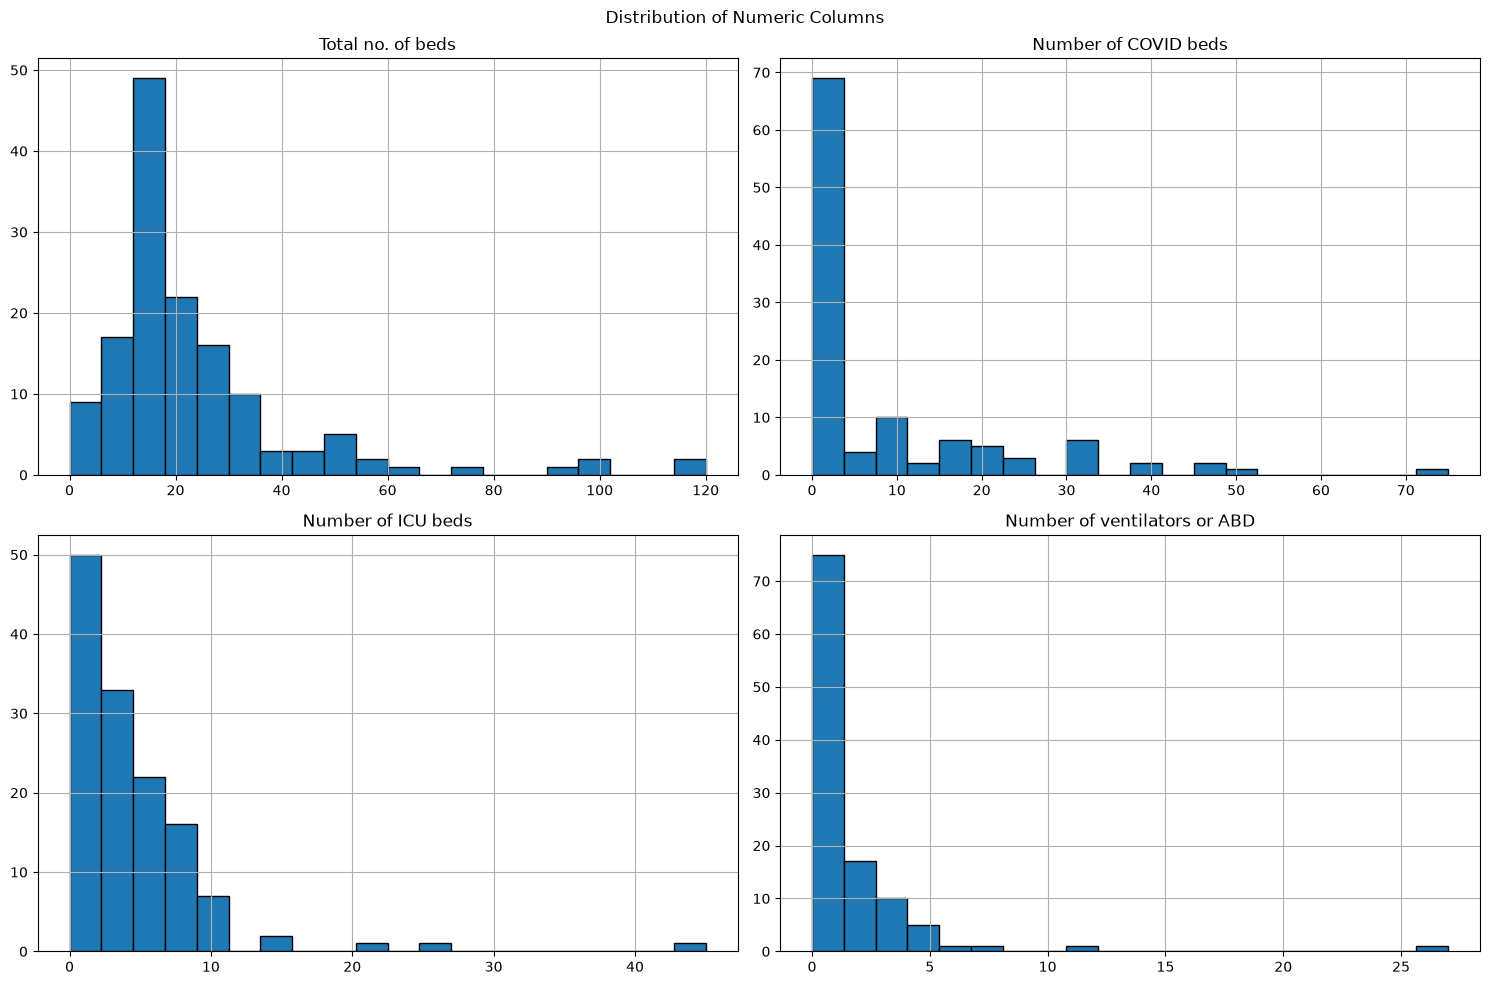

In [40]:
df[numeric_columns].hist(
    figsize=(15, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numeric Columns")
plt.tight_layout()
plt.savefig("distribution_numeric.png", dpi=300)
plt.show()

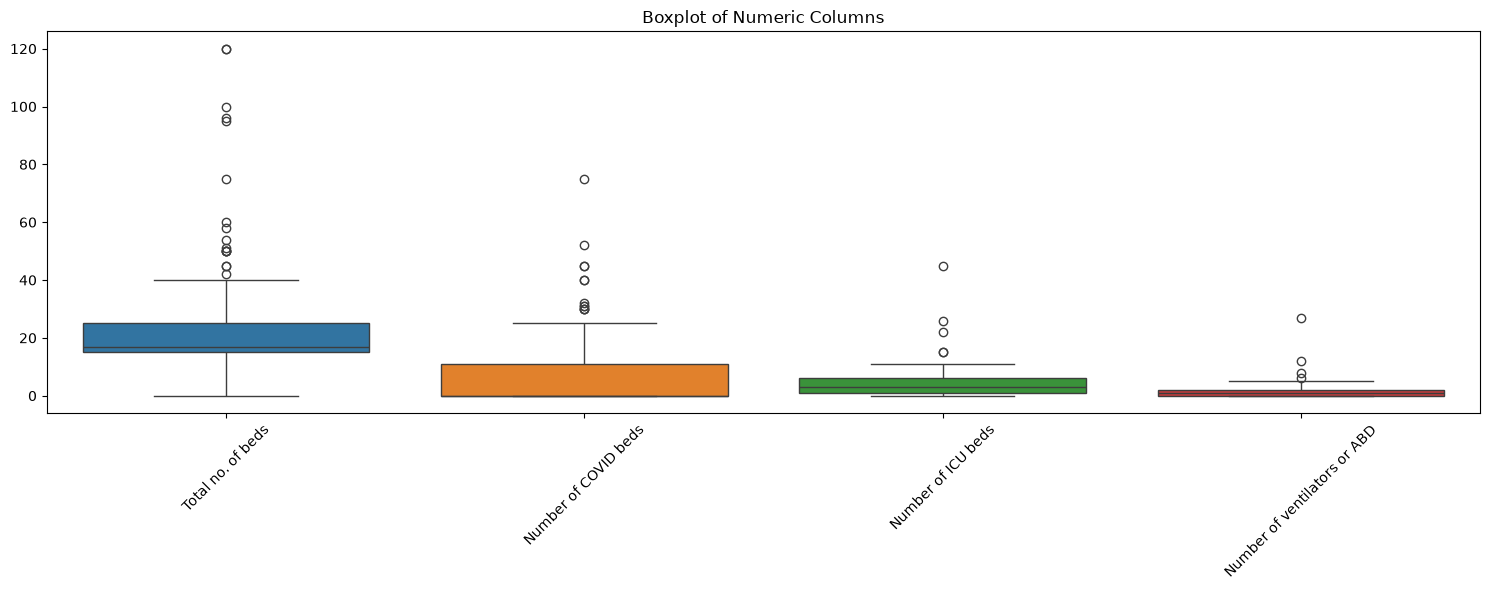

In [16]:
plt.figure(figsize=(15, 6))

sns.boxplot(data=df[numeric_columns])

plt.title("Boxplot of Numeric Columns")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

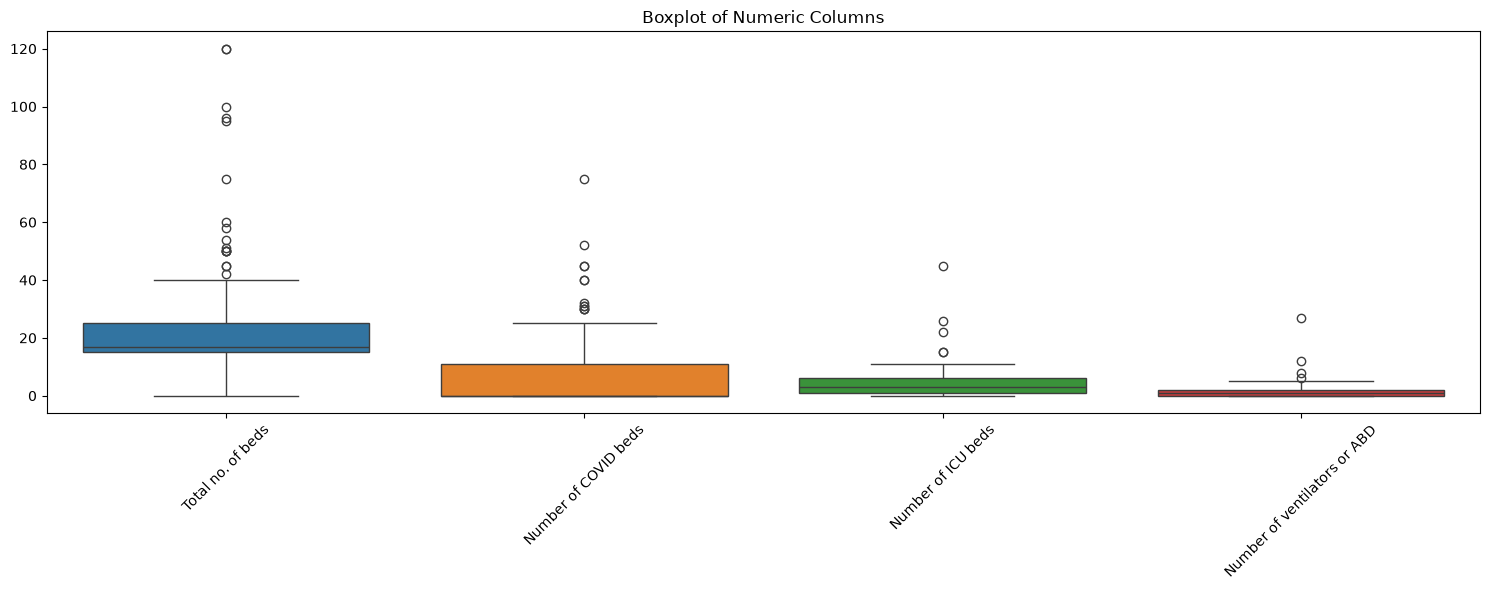

In [19]:
plt.figure(figsize=(15, 6))

sns.boxplot(data=df[numeric_columns])

plt.title("Boxplot of Numeric Columns")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("numeric_boxplots.png", dpi=300)
plt.show()

In [21]:
correlation = df[numeric_columns].corr()

correlation

,Total no. of beds,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD
Total no. of beds,1.000000,0.734387,0.405475,0.405044
Number of COVID beds,0.734387,1.000000,0.566336,0.532457
Number of ICU beds,0.405475,0.566336,1.000000,0.742088
Number of ventilators or ABD,0.405044,0.532457,0.742088,1.000000


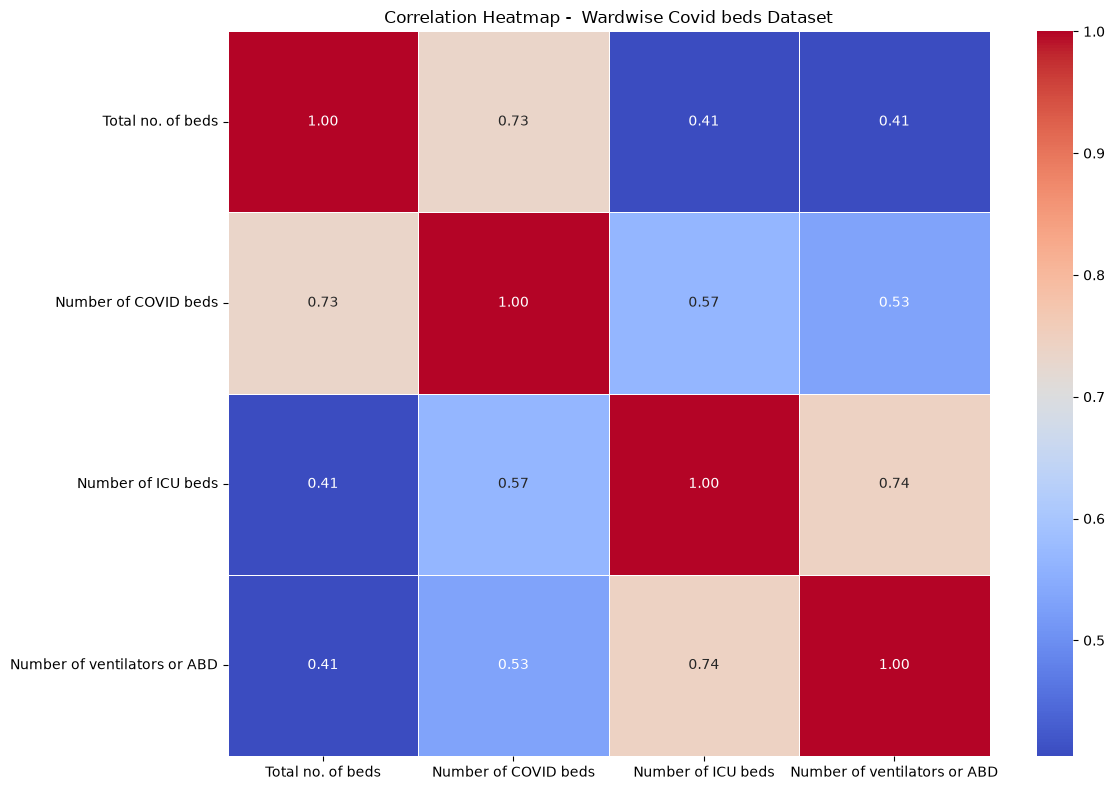

In [25]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap -  Wardwise Covid beds Dataset")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)

plt.show()

In [27]:
corr_pairs = correlation.unstack()

corr_pairs = corr_pairs[
    (corr_pairs < 1) & (corr_pairs > -1)
]

print(corr_pairs.sort_values(
    ascending=False
).head(10))

Number of ICU beds            Number of ventilators or ABD    0.742088
Number of ventilators or ABD  Number of ICU beds              0.742088
Total no. of beds             Number of COVID beds            0.734387
Number of COVID beds          Total no. of beds               0.734387
                              Number of ICU beds              0.566336
Number of ICU beds            Number of COVID beds            0.566336
Number of ventilators or ABD  Number of COVID beds            0.532457
Number of COVID beds          Number of ventilators or ABD    0.532457
Number of ICU beds            Total no. of beds               0.405475
Total no. of beds             Number of ICU beds              0.405475
dtype: float64


In [29]:
print(corr_pairs.sort_values().head(10))

Total no. of beds             Number of ventilators or ABD    0.405044
Number of ventilators or ABD  Total no. of beds               0.405044
Number of ICU beds            Total no. of beds               0.405475
Total no. of beds             Number of ICU beds              0.405475
Number of ventilators or ABD  Number of COVID beds            0.532457
Number of COVID beds          Number of ventilators or ABD    0.532457
                              Number of ICU beds              0.566336
Number of ICU beds            Number of COVID beds            0.566336
Total no. of beds             Number of COVID beds            0.734387
Number of COVID beds          Total no. of beds               0.734387
dtype: float64


In [31]:
summary = df.describe()

summary

,Total no. of beds,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD
count,143.000000,111.000000,133.000000,111.000000
mean,23.587413,8.108108,4.413534,1.531532
std,20.334640,13.698939,5.365614,3.068372
min,0.000000,0.000000,0.000000,0.000000
25%,15.000000,0.000000,1.000000,0.000000
50%,17.000000,0.000000,3.000000,1.000000
75%,25.000000,11.000000,6.000000,2.000000
max,120.000000,75.000000,45.000000,27.000000


In [33]:
df.describe(include="all")

,City Name,Area Name,Day-Month-Year,Ward No.,Ward Name,Type of hospital_PrivateorPublic,Longitude,Latitude,Total no. of beds,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD
count,181,179,176,169,179,168,111,111,143.000000,111.000000,133.000000,111.000000
unique,1,15,26,62,71,159,55,55,NaN,NaN,NaN,NaN
top,Kalyan Dombivali,KALYAN,44573,68,ramnagar,PRIVATE,0,0,NaN,NaN,NaN,NaN
freq,181,37,48,17,17,9,21,21,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.587413,8.108108,4.413534,1.531532
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.334640,13.698939,5.365614,3.068372
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.000000,0.000000,1.000000,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.000000,0.000000,3.000000,1.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25.000000,11.000000,6.000000,2.000000


In [35]:
summary_table = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Mode": df[numeric_columns].mode().iloc[0],
    "Standard Deviation": df[numeric_columns].std(),
    "Minimum": df[numeric_columns].min(),
    "Maximum": df[numeric_columns].max()
})

summary_table

,Mean,Median,Mode,Standard Deviation,Minimum,Maximum
Total no. of beds,23.587413,17.0,15.0,20.334640,0.0,120.0
Number of COVID beds,8.108108,0.0,0.0,13.698939,0.0,75.0
Number of ICU beds,4.413534,3.0,0.0,5.365614,0.0,45.0
Number of ventilators or ABD,1.531532,1.0,0.0,3.068372,0.0,27.0


In [38]:
summary_table.to_csv("summary_statistics.csv")

print("Summary statistics saved successfully!")

Summary statistics saved successfully!


In [39]:
df.describe(include="all").to_csv("eda_summary_report.csv")

print("EDA report saved successfully!")

EDA report saved successfully!
